# Baseline inference benchmark

Reproducible procedure. The measurements are produced by `benchmark.py`; this notebook only reads and summarises them (`baseline-results.csv` and the raw per-request latencies in `raw/`). **No number is typed by hand.**

## Protocol

1. **Fixed model**: `models:/ride-classifier@champion` (version recorded in every row).
2. **Representative data**: the 150 held-out test rides (`data.split_rides`, same split as training), raw CSV as the API receives it.
3. **Warm-up**: 10 predictions, not timed.
4. **Model level**: 200 timed calls of `pyfunc.predict` on 1 ride (`time.perf_counter`), split into preprocessing and network time.
5. **API level**: 200 timed `POST /predict` (1 ride per request), then a closed-loop load test of 20 s at concurrency 1, 4 and 8.
6. **Memory**: peak RSS of the benchmark process; RSS of the API process after each load test.
7. **Quality**: macro F1 and accuracy on the 150 rides.
8. **3 runs** of steps 4–6: we report the median and the min–max range.

CPU only: PyTorch runs on CPU (no CUDA/MPS), so no GPU synchronisation is needed for the timings.

## How to reproduce

```bash
# 1. a registry with the champion (here: local SQLite registry, model trained with the project code)
export MLFLOW_TRACKING_URI=sqlite:///$PWD/mlruns/mlflow.db
uv run python -m ride_classifier.data && uv run python -m ride_classifier.train
# 2. the API, 1 uvicorn worker (any free port)
uv run uvicorn ride_classifier.api:app --port 8010 &
# 3. the benchmark (about 5 minutes)
uv run python ai-infrastructure/benchmarks/benchmark.py --api-url http://localhost:8010 \
    --api-pid $(lsof -tiTCP:8010 -sTCP:LISTEN) --runs 3
```

To benchmark the production model instead, point `MLFLOW_TRACKING_URI` to the prod MLflow (`http://localhost:30500`).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

HERE = Path.cwd()
results = pd.read_csv(HERE / "baseline-results.csv")
conditions = results.iloc[0][["model_version", "runtime", "hardware", "date"]]
conditions

model_version                       ride-classifier v1 (@champion)
runtime                   PyTorch 2.15.0 CPU, MLflow 3.18.0 pyfunc
hardware         Apple M4 (4 torch threads, 16 GB RAM), Darwin ...
date                                                    2026-11-20
Name: 0, dtype: object

In [2]:
summary = (
    results.groupby(["metric", "concurrency", "unit"], sort=False)["value"]
    .agg(median="median", min="min", max="max", runs="count")
    .round(2)
)
summary

,,,median,min,max,runs
metric,concurrency,unit,,,,
process_peak_rss_after_load,1,MB,820.83,820.83,820.83,1
model_weights_size,1,MB,0.11,0.11,0.11,1
mlflow_model_artifact_size,1,MB,1.27,1.27,1.27,1
model_latency_mean,1,ms,2.04,1.83,2.25,3
model_latency_p50,1,ms,1.89,1.79,1.93,3
model_latency_p95,1,ms,2.97,2.64,4.83,3
model_latency_max,1,ms,6.02,3.70,9.76,3
model_throughput,1,rides/s,491.14,445.30,546.84,3
preprocessing_latency_mean,1,ms,0.50,0.48,0.51,3


## Latency distribution (all runs, 1 ride per call)

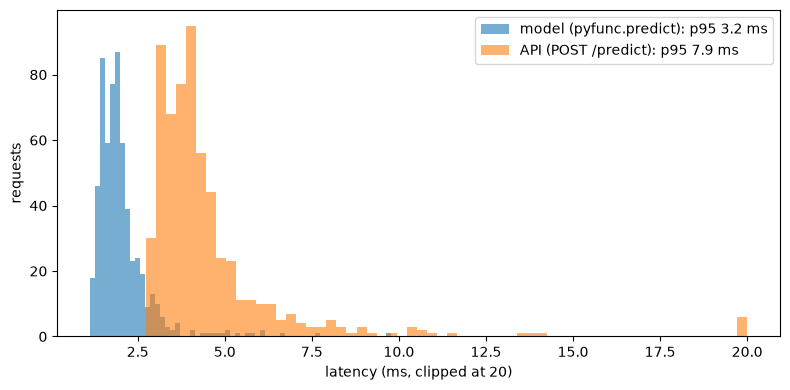

In [3]:
def raw(pattern: str) -> pd.Series:
    files = sorted((HERE / "raw").glob(pattern))
    return pd.concat([pd.read_csv(f)["latency_ms"] for f in files], ignore_index=True)


fig, ax = plt.subplots(figsize=(8, 4))
for label, pattern in [
    ("model (pyfunc.predict)", "run*_model_latency.csv"),
    ("API (POST /predict)", "run*_api_latency.csv"),
]:
    values = raw(pattern)
    ax.hist(values.clip(upper=20), bins=60, alpha=0.6, label=f"{label}: p95 {values.quantile(0.95):.1f} ms")
ax.set_xlabel("latency (ms, clipped at 20)")
ax.set_ylabel("requests")
ax.legend()
fig.tight_layout()

## API under load: throughput and p95 latency vs concurrency

metric,api_latency_p95_under_load,api_throughput
concurrency,,
1,7.9,206.0
4,32.3,205.7
8,57.9,232.5


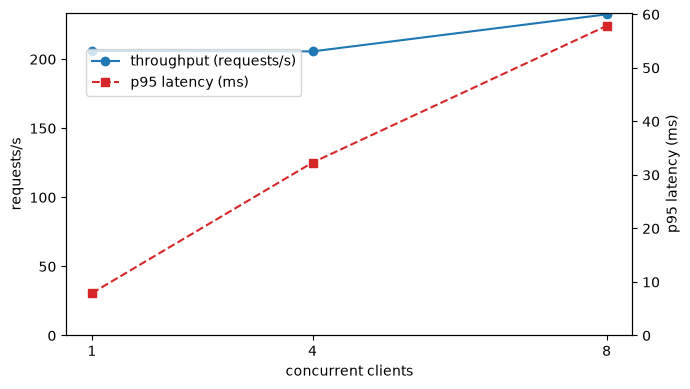

In [4]:
load = results[results["metric"].isin(["api_throughput", "api_latency_p95_under_load"])]
load = load.pivot_table(index="concurrency", columns="metric", values="value", aggfunc="median")

fig, ax1 = plt.subplots(figsize=(7, 4))
ax1.plot(load.index, load["api_throughput"], "o-", label="throughput (requests/s)")
ax1.set_xlabel("concurrent clients")
ax1.set_ylabel("requests/s")
ax1.set_ylim(0)
ax2 = ax1.twinx()
ax2.plot(load.index, load["api_latency_p95_under_load"], "s--", color="tab:red", label="p95 latency (ms)")
ax2.set_ylabel("p95 latency (ms)")
ax2.set_ylim(0)
fig.legend(loc="upper left", bbox_to_anchor=(0.12, 0.88))
ax1.set_xticks(load.index)
fig.tight_layout()
load.round(1)

## Interpretation

- **The model itself is fast**: about 2 ms per ride on one CPU process, of which ≈ 0.5 ms preprocessing and ≈ 0.8 ms CNN forward pass (≈ 9 windows of 600 × 6 per ride); the rest is pyfunc overhead (input schema check, DataFrame output).
- **The API adds ≈ 2 ms** (HTTP, multipart upload, CSV parsing, validation): ≈ 4 ms mean per request.
- **Throughput does not grow with concurrency** (≈ 200–230 requests/s at 1, 4 and 8 clients) while p95 latency grows roughly with the number of clients: requests are served **one at a time**. Cause: `/predict` is an `async def` endpoint that calls the model synchronously, which blocks the event loop of the single uvicorn worker. Scaling therefore comes from more workers / replicas (or a sync endpoint run in a thread pool), not from more concurrency on one process.
- **Memory**: the API process uses ≈ 200 MB after load (one run reached ≈ 440 MB: growth under load, to watch); the Kubernetes request of 768 Mi and limit of 2 Gi are generous for this model.
- **Conditions**: one Mac shared with other Docker stacks (see `raw/background-load.txt`); the spread between runs is reported as min–max.